# День 08. Упражнение 03
# Переобучение

## 0. Импорты

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from IPython.display import HTML, display
from sklearn.model_selection import train_test_split
from collections import Counter
from sklearn.model_selection import cross_val_score
import joblib
from sklearn.metrics import confusion_matrix, classification_report, _plot
from sklearn.model_selection import GridSearchCV

## 1. Предобработка

1. Прочитай файл `dayofweek.csv` в DataFrame.

In [3]:
df = pd.read_csv("../data/dayofweek.csv")
df.shape

(1686, 44)

In [4]:
y = df["dayofweek"]
X = df.drop(columns=["dayofweek"])

2. Используя `train_test_split` с параметрами `test_size=0.2`, `random_state=21`, получи `X_train`, `y_train`, `X_test`, `y_test`.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21
)
df_compare = pd.DataFrame(
    {
        "Train": y_train.value_counts(normalize=True),
        "Test": y_test.value_counts(normalize=True),
    }
)

3. С помощью, например, `value_counts()` проверь, похожее ли распределение классов в train и test.

4. Добавь параметр `stratify=` и проверь распределение снова — теперь оно должно быть более-менее одинаковым в обоих наборах данных.

In [6]:
# С параметром stratify=y: Алгоритм сначала считает пропорции дней недели во всем исходном датасете, а затем жестко следит за тем, чтобы и в Train (80% строк), и в Test (20% строк) эти пропорции сохранились в точности до процента.
# простыми словами: главный смысл стратификации — сделать Train и Test одинаковыми между собой
# почему это важно?  напр, у нас есть дисбаланс классов: чт — очень популярный день, а сб. и вскр. — редкие). Параметр страхует код от случайных перекосов при делении, что гарантирует, что в тестовую и трейн выборку попадет та же доля более редкого класса.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y
)
df_compare["Train stratified"] = y_train.value_counts(normalize=True)
df_compare["Test stratified"] = y_test.value_counts(normalize=True)

print(
    "стратификация гарантирует, что в тестовую и трейн выборку попадет\nпрактически одинаковая доля из каждого класса"
)
df_compare

стратификация гарантирует, что в тестовую и трейн выборку попадет
практически одинаковая доля из каждого класса


,Train,Test,Train stratified,Test stratified
dayofweek,,,,
0,0.077893,0.091716,0.080861,0.079882
1,0.164688,0.153846,0.162463,0.162722
2,0.092730,0.071006,0.088279,0.088757
3,0.232196,0.245562,0.234421,0.236686
4,0.059347,0.071006,0.061573,0.062130
5,0.160237,0.162722,0.160979,0.159763
6,0.212908,0.204142,0.211424,0.210059


## 2. Базовые модели

1. Обучи те же самые базовые модели из предыдущего упражнения и вычисли accuracy, используя тестовый набор данных со стратификацией.
2. Все ли модели показали похожие значения метрики? Какая из них показала наибольшее отличие по сравнению с предыдущим упражнением? Напиши ответ в markdown-ячейке в конце раздела.

### a. Логистическая регрессия

In [7]:
# в разделе 3 данного задания авторы в итоге указывают, что использовали логистическую регрессию с `solver='liblinear', так что решила вернуться "в прошлое" и еще раз просчитать этот вариант.
# в старых версиях scikit-learn (до 1.5) встроенный параметр multi_class='ovr' калибровал вероятности внутри самого liblinear совершенно иначе, чем внешняя обёртка OneVsRestClassifier(LogisticRegression(solver='liblinear')) делает это сейчас на новых библиотеках.

model_liblinear = LogisticRegression(
    solver="liblinear", fit_intercept=False, random_state=21, max_iter=1000
)
# model_liblinear.fit(X_train, y_train) # The 'liblinear' solver does not support multiclass classification (n_classes >= 3). Either use another solver or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.

# поэтому попробовала:
model_liblinearOVR = OneVsRestClassifier(model_liblinear)
model_liblinearOVR.fit(X_train, y_train)

acc = accuracy_score(y_test, model_liblinearOVR.predict(X_test))
lr_accuracy = {"liblinearOVR": acc}
trained_lr_models = {"liblinearOVR": model_liblinearOVR}
acc

0.6153846153846154

In [ ]:
# логичнее попробовать другие солверы более подходящие для мультиклассовой задачи.
solvers = ["newton-cg", "saga", "lbfgs"]

for s in solvers:
    model = LogisticRegression(
        solver=s, fit_intercept=False, random_state=21, max_iter=1000
    )
    model.fit(X_train, y_train)

    acc = accuracy_score(y_test, model.predict(X_test))
    lr_accuracy[s] = acc
    trained_lr_models[s] = model

for k, v in lr_accuracy.items():
    print(f"{f'Точность с {k}:':<26}{v}")

most_common_acc = Counter(lr_accuracy.values()).most_common(1)[0][0]
print(f"accuracy для модели логистической регресии: {most_common_acc}")

Точность с liblinearOVR:  0.6153846153846154
Точность с newton-cg:     0.6272189349112426
Точность с saga:          0.6272189349112426
Точность с lbfgs:         0.6331360946745562
Принятая accuracy для модели логистической регресии: 0.6272189349112426


In [137]:
# разбор most_common_acc = Counter(lr_accuracy.values()).most_common(1)[0][0]
lr_accuracy = {"newton-cg": 0.6272, "saga": 0.6272, "lbfgs": 0.6331}
print(lr_accuracy.values())
print(Counter(lr_accuracy.values()))
print(Counter(lr_accuracy.values()).most_common(1))  # кортеж внутри списка
print(Counter(lr_accuracy.values()).most_common(1)[0][0])

dict_values([0.6272, 0.6272, 0.6331])
Counter({0.6272: 2, 0.6331: 1})
[(0.6272, 2)]
0.6272


### b. SVM

In [13]:
model_svc = SVC(kernel="linear", random_state=21, probability=True)
model_svc_ovr = OneVsRestClassifier(model_svc)

model_svc.fit(X_train, y_train)
model_svc_ovr.fit(X_train, y_train)

accuracy_svc_test = accuracy_score(y_test, model_svc.predict(X_test))
accuracy_svc_ovr_test = accuracy_score(y_test, model_svc_ovr.predict(X_test))

# print(f"Accuracy для модели SVC: {accuracy_svc_test}")
print(f"Accuracy для модели SVC (OVR): {accuracy_svc_ovr_test}")

Accuracy для модели SVC (OVR): 0.6183431952662722


### c. Дерево решений

In [139]:
# Accuracy для DT в ex02 была 0.5516014234875445
model_dt = DecisionTreeClassifier(max_depth=4, random_state=21)
model_dt.fit(X_train, y_train)
y_pred_dt_test = model_dt.predict(X_test)
accuracy_dt_test = accuracy_score(y_test, y_pred_dt_test)
print(f"Accuracy для модели DT: {accuracy_dt_test}")

Accuracy для модели DT: 0.5295857988165681


### d. Случайный лес

In [140]:
model_rf = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
model_rf.fit(X_train, y_train)
y_pred_rf_test = model_rf.predict(X_test)
accuracy_rf_test = accuracy_score(y_test, y_pred_rf_test)
accuracy_rf_test

0.9289940828402367

## 3. Кросс-валидация

Можно было бы “поиграть” с параметрами модели, чтобы добиться более высокой точности на тестовом наборе, но так делать не принято. Такая тактика снова приводит к переобучению. Тестовый набор предназначен только для финальной проверки качества модели.

Однако есть другой способ решения этой задачи — кросс-валидация. Он не использует тестовый набор, а создает дополнительное разбиение обучающего набора. Существует несколько способов реализации, но общая идея одна: появляется валидационный набор, который используется для подбора гиперпараметров.

1. Используя `cross_val_score` с параметром `cv=10`, вычисли среднее значение accuracy и стандартное отклонение для каждой модели, использованной ранее (логистическая регрессия с `solver='liblinear'`, SVC, дерево решений, случайный лес).

### a. Логистическая регрессия

In [100]:
LRliblinearModel = LogisticRegression(
    solver="liblinear", fit_intercept=False, random_state=21, max_iter=1000
)

LRliblinearModelOVR_ = OneVsRestClassifier(LRliblinearModel)
LRliblinearModelOVR_.fit(X_train, y_train)


,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...r='liblinear')
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default

In [101]:
score_lr = cross_val_score(
    LRliblinearModelOVR_, X_train, y_train, cv=10, scoring="accuracy", n_jobs=-1
)

In [ ]:
LR_mean_acc = score_lr.mean()
LR_std_acc = score_lr.std()
print(
    f"Logistic Regression Model\n{'--' * 20}\n{'mean_accuracy:':<16}{LR_mean_acc}\n{'std:':<16}{LR_std_acc}"
)
# Было до кросс-валидации: 0.6272189349112426

Logistic Regression Model
----------------------------------------
mean_accuracy:  0.5815975677169707
std:            0.025322132907253592


### b. SVM

In [10]:
SVCModel = SVC(kernel="linear", random_state=21, probability=True)
SVCModelOVR = OneVsRestClassifier(SVCModel)

SVCModelOVR.fit(X_train, y_train)
SVCModel.fit(X_train, y_train)

score_svc = cross_val_score(
    SVCModel, X_train, y_train, cv=10, scoring="accuracy", n_jobs=-1
)

score_svc_ovr = cross_val_score(
    SVCModelOVR, X_train, y_train, cv=10, scoring="accuracy", n_jobs=-1
)

In [12]:
SVC_mean_acc = score_svc.mean()
SVC_std_acc = score_svc.std()

SVC_mean_acc_ovr = score_svc_ovr.mean()
SVC_std_acc_ovr = score_svc_ovr.std()

print(
    f"SVC model\n{'--' * 20}\n{'mean_accuracy:':<16}{SVC_mean_acc}\n{'std:':<16}{SVC_std_acc}"
)
print()
print(
    f"SVC OVR model\n{'--' * 20}\n{'mean_accuracy:':<16}{SVC_mean_acc_ovr}\n{'std:':<16}{SVC_std_acc_ovr}"
)

# Было до кросс-валидации:
# для модели SVC: 0.7159763313609467
# для модели SVC (OVR): 0.6183431952662722

SVC model
----------------------------------------
mean_accuracy:  0.6587064676616916
std:            0.043585708770590564

SVC OVR model
----------------------------------------
mean_accuracy:  0.5705085682697624
std:            0.037010421284044116


### c. Дерево решений

In [ ]:
DTModel = DecisionTreeClassifier(max_depth=4, random_state=21)
DTModel.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",21
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [82]:
score_dt = cross_val_score(
    DTModel, X_train, y_train, cv=10, scoring="accuracy", n_jobs=-1
)

In [ ]:
DT_mean_acc = score_dt.mean()
DT_std_acc = score_dt.std()

print(
    f"Decision Tree model\n{'--' * 20}\n{'mean_accuracy:':<16}{DT_mean_acc}\n{'std:':<16}{DT_std_acc}"
)

# Было до кросс-валидации: 0.5295857988165681

Decision Tree model
----------------------------------------
mean_accuracy:  0.5088944168048645
std:            0.031903139495514356


### d. Случайный лес

In [17]:
RFModel = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
RFModel.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",25
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [18]:
score_rf = cross_val_score(
    RFModel, X_train, y_train, cv=10, scoring="accuracy", n_jobs=-1
)

In [19]:
RF_mean_acc = score_rf.mean()
RF_std_acc = score_rf.std()

print(
    f"Random Forest model\n{'--' * 20}\n{'mean_accuracy:':<16}{RF_mean_acc}\n{'std:':<16}{RF_std_acc}"
)
# Было до кросс-валидации: 0.9289940828402367

Random Forest model
----------------------------------------
mean_accuracy:  0.9176561636263129
std:            0.02159583796321821


## 4. Оптимизация

1. Выбери лучшую модель и немного поиграй с её параметрами на кросс-валидации, чтобы найти достаточно хорошие параметры или их комбинацию.

In [36]:
print(
    f"Лучшая модель: Random Forest\n{'--' * 20}\n{'mean_accuracy:':<16}{RF_mean_acc}\n{'std:':<16}{RF_std_acc}"
)
# ее базовые настройки:
# RFModel = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
# RFModel.fit(X_train, y_train)
# score_rf = cross_val_score(
#     RFModel, X_train, y_train, cv=10, scoring="accuracy", n_jobs=-1
# )

Лучшая модель: Random Forest
----------------------------------------
mean_accuracy:  0.9176561636263129
std:            0.02159583796321821


In [ ]:
# в курсе Бурмистрова ML 17.3-17.4 говорится в основном о настройке
# n_estimators  - кол-во деревьев решений 100 по умолчанию
# max_features - кол-во признаков в каждом поднаборе. по умолчанию берется корень от кол-ва признаков, то есть sqrt(43)
# bootstrap=True по умолчанию то есть для построения деревьев исп-ся поднаборы с вовзращением: то есть из множества признаков случайно выбирается нужное кол-во "с повтороением" - привет Райгородский. если отключить его то при увеличении кол-ва деревьев мы будем получать сильно кореллирующие между собой (17.5), при включенном параметре этот момент наступает позже.
# oob_score=False  out of bag errors - это те данные, что не попали в выборки и получается что их м.исп-ть как тест.набор данных для данного конкретного дерева
# Этот пар-р не влияет на пр-с обучения модели так что в пролет
# термин bagging это b (bootsrtapped data) + ag (aggregated prediction)
# по умолчанию критерион = 'gini'. м.попробовать "entropy"

param_grid = {
    "n_estimators": [50, 100, 150],
    "max_features": ["sqrt", 0.3, "log2"],
    "bootstrap": [True, False],
    "criterion": ["entropy", "gini"],
    "max_depth": [15, 20, 25, 30],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(max_depth=25, random_state=21),
    param_grid=param_grid,
    cv=10,
    n_jobs=-1,
    scoring="accuracy",  #  или др.метрики: 'f1', 'roc_auc'
)
grid_search.fit(X_train, y_train)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший результат:", grid_search.best_score_)


Лучшие параметры: {'bootstrap': False, 'criterion': 'gini', 'max_depth': 30, 'max_features': 'log2', 'n_estimators': 150}
Лучший результат: 0.9221116639027087


In [56]:
RFModel_final = grid_search.best_estimator_
RFModel_final.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",30
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",False
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(

In [57]:
score_rf_final = cross_val_score(
    RFModel_final, X_train, y_train, cv=10, scoring="accuracy", n_jobs=-1
)

In [59]:
RF_mean_acc = score_rf_final.mean()
RF_std_acc = score_rf_final.std()

print(
    f"Random Forest model (final vers.)\n{'--' * 20}\n{'mean_accuracy:':<16}{RF_mean_acc}\n{'std:':<16}{RF_std_acc}"
)

# для базы было:
# mean_accuracy:  0.9176561636263129
# std:            0.02159583796321821

Random Forest model (final vers.)
----------------------------------------
mean_accuracy:  0.9221116639027087
std:            0.015250918084997669


2. Вычисли accuracy для финальной модели на тестовом наборе данных.

In [62]:
y_pred_final_test = RFModel_final.predict(X_test)
final_test_accuracy = accuracy_score(y_test, y_pred_final_test)
print(f"Accuracy финальной модели на тесте: {final_test_accuracy}")

Accuracy финальной модели на тесте: 0.9349112426035503


3. Построй график, отображающий 10 самых важных признаков для этой модели.

In [54]:
def draw_barh_for_feature_importances(
    importance_data, feature_names, top_n=10, model_name=None
):

    if importance_data.ndim == 2:
        final_data = np.sum(np.abs(importance_data), axis=0)
    else:
        final_data = importance_data

    df = pd.DataFrame(
        index=feature_names,
        data=final_data,
        columns=["Важность признаков"],
    ).nlargest(top_n, "Важность признаков")

    plt.figure(figsize=(8, 4))

    plt.barh(
        df.index[::-1], df["Важность признаков"][::-1], color="royalblue", alpha=0.8
    )

    plt.xlabel(
        "Суммарная абсолютная важность (Сумма |weights|)", fontsize=10, labelpad=15
    )
    plt.ylabel("")
    plt.title(
        f"Топ-{top_n} наиболее важных признаков"
        if model_name is None
        else f"Топ-{top_n} наиболее важных признаков модели {model_name}",
        fontsize=12,
        pad=15,
    )
    plt.tick_params(axis="both", labelsize=9, pad=5)
    plt.tight_layout()
    plt.show()

    html_table = df.round(4).to_html(classes="table table-striped")

    display(
        HTML(f"""
    <details style="margin-top: 15px; margin-bottom: 15px; cursor: pointer;">
        <summary style="font-weight: bold; color: #212529; padding: 5px; outline: none;">
            🏦2️⃣1️⃣ Нажмите, чтобы посмотреть точные числовые значения важности признаков
        </summary>
        <div style="padding: 10px 0;">
            {html_table}
        </div>
    </details>
    """)
    )
    return df

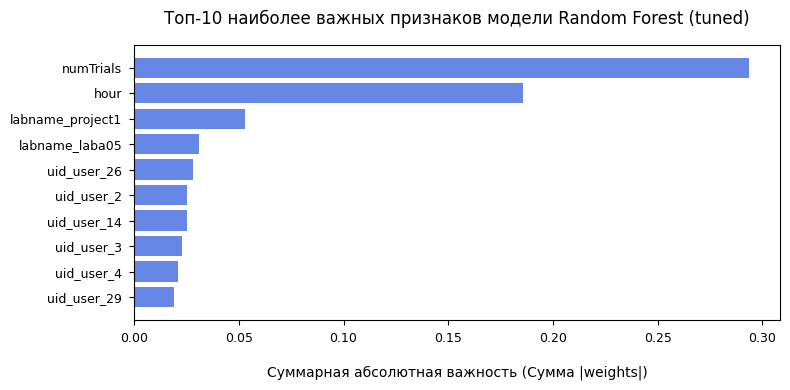

,Важность признаков
numTrials,0.2937
hour,0.1857
labname_project1,0.0529
labname_laba05,0.0311
uid_user_26,0.0282
uid_user_2,0.0254
uid_user_14,0.0253
uid_user_3,0.0227
uid_user_4,0.0208
uid_user_29,0.0192


In [61]:
df_rf = draw_barh_for_feature_importances(
    RFModel_final.feature_importances_, X.columns, model_name="Random Forest (tuned)"
)

4. Сохрани модель с помощью `joblib`.

In [69]:
joblib.dump(RFModel_final, "../data/random_forest_model.joblib");

5. Загрузи модель, сделай предсказания для тестового набора и вычисли accuracy.

In [70]:
loaded_model = joblib.load("../data/random_forest_model.joblib")
y_pred_loaded = loaded_model.predict(X_test)
loaded_accuracy = accuracy_score(y_test, y_pred_loaded)

print(
    f"Accuracy загруженной модели: {loaded_accuracy}\nAccuracy сохраненной модели: {final_test_accuracy}"
)

Accuracy загруженной модели: 0.9349112426035503
Accuracy сохраненной модели: 0.9349112426035503
